# **Exercise 2: Classification Task** - *Classifying Heart Disease*
For this exercise, this task applies binary classification to predict whether a patient has a heart disease. In doing so, I have derived a dataset from Kaggle uploaded by David Lapp with over 1,025 patient records that consists of 13 features namely: age, sex, chest pain type, resting blood pressure, cholesterol, maximum heart rate, and exercise-induced angina.

# ***Loading Libraries***

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, precision_recall_curve, average_precision_score
)

# ***Loading Dataset***

In [36]:
data = pd.read_csv("/kaggle/input/datasets/juyams/heart-disease/heart.csv")

In [37]:
data

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1


In [38]:
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [39]:
data.shape

(1025, 14)

In [40]:
data.info

<bound method DataFrame.info of       age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
0      52    1   0       125   212    0        1      168      0      1.0   
1      53    1   0       140   203    1        0      155      1      3.1   
2      70    1   0       145   174    0        1      125      1      2.6   
3      61    1   0       148   203    0        1      161      0      0.0   
4      62    0   0       138   294    1        1      106      0      1.9   
...   ...  ...  ..       ...   ...  ...      ...      ...    ...      ...   
1020   59    1   1       140   221    0        1      164      1      0.0   
1021   60    1   0       125   258    0        0      141      1      2.8   
1022   47    1   0       110   275    0        0      118      1      1.0   
1023   50    0   0       110   254    0        0      159      0      0.0   
1024   54    1   0       120   188    0        1      113      0      1.4   

      slope  ca  thal  target  
0         2

Similarly, binary labels are used to indicate whether an individual has heart disease. The following shows the binary label:
* Heart Disease = 1
* No Heart Disease = 0	

In [41]:
print("Missing values:\n", data.isnull().sum())
print("\nClass distribution:\n", data['target'].value_counts())

Missing values:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Class distribution:
 target
1    526
0    499
Name: count, dtype: int64


Based on my initial findings, there are zero missing values and a nearly target distribution which reveals that there are over 526 positive cases vs 499 negative cases.

# ***Selection of X and Y***

In [42]:
X = data[['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']]

During preprocessing, all 13 clinical predictors were already stored in numerical format unlike in the first exercise where one-hot encoding was implemented since there was one categorical element.

In [43]:
X

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2


In [44]:
y = data['target']

In [45]:
y

0       0
1       0
2       0
3       0
4       0
       ..
1020    1
1021    0
1022    0
1023    1
1024    0
Name: target, Length: 1025, dtype: int64

# ***Splitting the Data***

In [46]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

I split the dataset into 80% training and 20% testing, while I also applied StandardScaler (for training set) to the variables with larger numeric ranges, like cholesterol and blood pressure, to prevent it from overshadowing the model. 

In [47]:
X_train.shape

(820, 13)

In [48]:
X_test.shape

(205, 13)

In [49]:
scaler = StandardScaler()

Though feature scaling was not previously discussed in class based on what I could remember, I have done further research on Logistic Regression Optimisation. Upon learning more, this highlights the importance of standardisation when clinical predictors operate on multiple different numerical scales. According to James et al. (2021), they stated that by applying the StandardScaler, this transforms each feature to have a mean of 0, while a standard deviation of 1. This then ensures that larger variables do not unevenly influence model weights.

In [50]:
X_train_scaled = scaler.fit_transform(X_train)

In [51]:
print("X_train shape:", X_train_scaled.shape)

X_train shape: (820, 13)


In [52]:
X_test_scaled = scaler.transform(X_test)

In [53]:
print("X_test shape:", X_test_scaled.shape)

X_test shape: (205, 13)


# ***Model Training***

In [54]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

**blue** means it successfully trained the model. It's ready for testing

# ***Model Testing***

In [55]:
y_pred = model.predict(X_test_scaled)

In [56]:
y_prob = model.predict_proba(X_test_scaled)[:, 1]

Probabilities needed for ROC & Precision-Recall curves

In [57]:
y_pred

array([1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0,
       0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0,
       0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0,
       1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0,
       1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1,
       0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1,
       1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0,
       1, 1, 1, 1, 1, 0, 0])

predicted values by the computer/algorithm

# **Evaluating Model**

In [58]:
accuracy = accuracy_score(y_test, y_pred)

In [59]:
print(f"Accuracy:  {accuracy:.4f}")

Accuracy:  0.7951


In [60]:
precision = precision_score(y_test, y_pred)

In [61]:
print(f"Precision: {precision:.4f}")

Precision: 0.7563


In [62]:
recall = recall_score(y_test, y_pred)

In [63]:
print(f"Recall:    {recall:.4f}")

Recall:    0.8738


In [64]:
f1 = f1_score(y_test, y_pred)

In [65]:
print(f"F1-Score:  {f1:.4f}")

F1-Score:  0.8108


Since the focus for this exercise is to use Logistic Regression, the model was trained on the features mentioned in the latter paragraphs to estimate whether a patient has a heart disease. Based on the test, the model achieved an Accuracy of 79.51% (0.7951), Precision of 75.63% (0.7563), Recall of 87.38% (0.8738), and an F1-Score of 0.8108.

# ***Visualizing Results***

**1. Confusion Matrix**

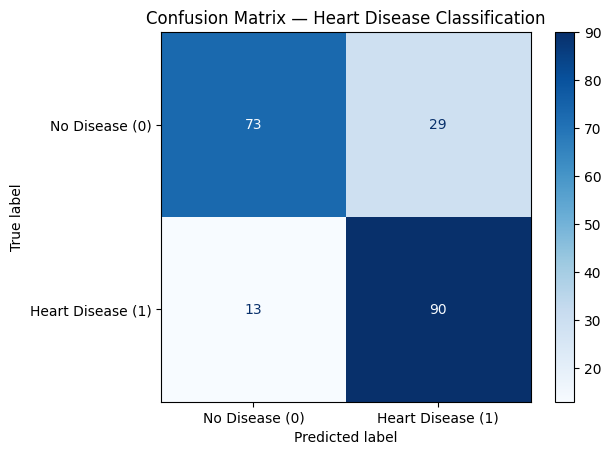

In [66]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Disease (0)', 'Heart Disease (1)'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix — Heart Disease Classification")
plt.show()

The Confusion Matrix above shows 90 true positives and 73 true negatives, alongside 29 false positives and only 13 false negatives. This was taken from the 205 test predictions into four clear outcomes. In a medical screening context, it is reported that achieving a high recall of 87.38% and keeping false negatives low is especially valuable. Applying such a case in the real-world, sending a healthy patient for extra follow-up tests (29 false positives) can be an inconvenience to some, whereas telling a patient with heart disease that they are healthy (13 false negatives) carries far more serious health risk.

**2. ROC Curve**

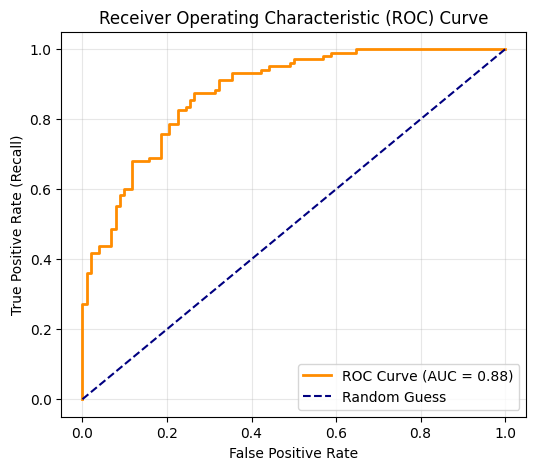

In [67]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

Moving on to the ROC Curve, the result shows that it bows sharply toward the top-left corner with an Area Under the Curve (AUC) of 8.8. This typically means that the model ranks a randomly chosen heart disease patient higher in risk than a healthy patient 88% of the time across all decision limits. 

**3. Precision-Recall Curve**

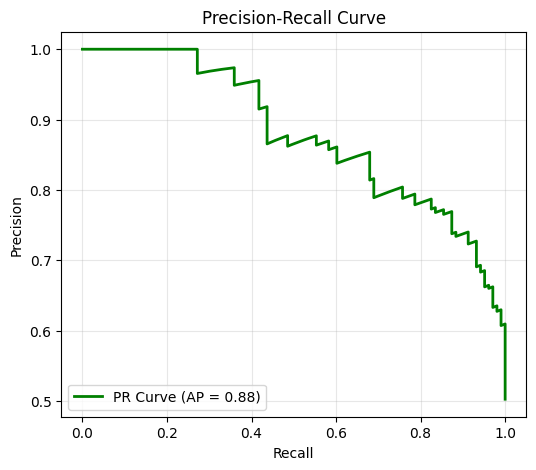

In [68]:
precision_vals, recall_vals, _ = precision_recall_curve(y_test, y_prob)
avg_precision = average_precision_score(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(recall_vals, precision_vals, color='green', lw=2, label=f'PR Curve (AP = {avg_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.grid(alpha=0.3)
plt.show()

Similarly, the Precision-Recall Curve maintains an Average Precision of 0.88, which also indicates that the model keeps false alarms reasonably low despite it pushing to catch more positive heart disease cases.

# ***Conclusion & Key Takeaways***

Though despite solid baseline performance, there are still some key limitations presented upon doing the exercise. I have observed that since the dataset combines multiple hospital cohorts, duplicate records can increase the evaluation metrics and could cause the risk of overfitting if identical patient profiles appear across splits. In addition, I noticed that keeping multi-category variables such as chest pain type and thalassemia as single integer columns assumes an artificial numerical order between categories. In comparison, one-hot encoding paired with tree-based models like Random Forest could potentially capture non-linear clinical patterns more effectively in future iterations. Though with my limited knowledge to the subject, sticking with Logical Regression is sufficient enough for starters.